
# Week 6 — Feature Engineering and Model Comparison

This notebook completes the Week 6 requirements:

1. Read the school-district-enriched property dataset.
2. Create a **bed/bath ratio**.
3. Create **property age in years**.
4. Include the **school district** as a detailed geographic feature.
5. Re-train the models using:
   - the old feature set;
   - the new feature set.
6. Create and save a table comparing old versus new model performance.

The notebook assumes it is stored in the main `IDX Exchange` folder and the input file is:

```text
results/enriched_data_with_school_district.csv
```

Outputs are saved in:

```text
results/06/
```


## 1. Import packages

In [1]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)


## 2. Set file paths

In [2]:

from pathlib import Path

file_name = "enriched_data_with_school_district.csv"

# Find the IDX Exchange project folder automatically
current_folder = Path.cwd().resolve()

project_root = None

for folder in [current_folder] + list(current_folder.parents):
    possible_file = folder / "data" / file_name

    if possible_file.exists():
        project_root = folder
        break

if project_root is None:
    raise FileNotFoundError(
        "Cannot find the data folder or enriched dataset. "
        "Check that the file is inside IDX Exchange/data."
    )

# Input dataset
data_path = project_root / "data" / file_name

# Output folder
output_dir = project_root / "results" / "Updated notebook + table comparing"
output_dir.mkdir(parents=True, exist_ok=True)

print("Current notebook folder:", current_folder)
print("Project folder:", project_root)
print("Input file:", data_path)
print("Output folder:", output_dir)


Current notebook folder: C:\Users\18327\IDX Exchange\results
Project folder: C:\Users\18327\IDX Exchange
Input file: C:\Users\18327\IDX Exchange\data\enriched_data_with_school_district.csv
Output folder: C:\Users\18327\IDX Exchange\results\Updated notebook + table comparing


## 3. Read the enriched dataset

In [3]:

if not data_path.exists():
    raise FileNotFoundError(
        f"Cannot find {data_path}. "
        "Make sure this notebook is saved in the main 'IDX Exchange' folder."
    )

df = pd.read_csv(data_path, low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (23260, 79)


,BuyerAgentAOR,ListAgentAOR,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,DistrictName
0,OutOfAreaBoard,CitrusValley,NaN,True,NaN,NaN,False,635000.0,1171672853,mike@bhfmortgage.com,2026-05-26,635000.0,Michael,Wallace,33.765292,-118.178346,1140 E Ocean,Residential,684.0,635000.0,0,"BETTER HOME FINANCIAL, INC",Compass,NaN,Michael Wallace,NaN,NaN,CLW-C145499,Zara,Baghikyan,NaN,Monthly,NaN,1171672853,"4 - Downtown Area, Alamitos Beach",NaN,Los Angeles,Closed,NaN,False,1.0,NaN,Condominium,1.3120,Alamitos Beach (AB),OutOfAreaBoard,1973.0,1140.0,CV26118073,1.0,Long Beach,NaN,NaN,1.0,2026-05-26,NaN,NaN,2026-03-15,2026-03-15,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,57149.0,1.0,False,1.0,Long Beach Unified,90802,785.0,57149.0,NaN,Long Beach Unified
1,SouthBay,SouthBay,Wood,True,NaN,NaN,False,8712500.0,1171668711,EK@ITZSOLD.COM,2026-05-28,8712500.0,Edward,Kaminsky,33.888972,-118.412712,212 18th Street,Residential,4269.0,8712500.0,0,"eXp Realty of California, Inc","eXp Realty of California, Inc",NaN,Edward Kaminsky,NaN,NaN,SKAMIEDW,Edward,Kaminsky,NaN,NaN,NaN,1171668711,142 - Manhattan Bch Sand,NaN,Los Angeles,Closed,NaN,True,4.0,NaN,SingleFamilyResidence,0.0621,NaN,SouthBay,2004.0,212.0,SB26116787,6.0,Manhattan Beach,NaN,NaN,5.0,2026-05-28,NaN,NaN,2024-10-30,2024-10-30,NaN,NaN,CA,NaN,NaN,True,NaN,NaN,ThreeOrMore,NaN,2703.0,2.0,False,4.0,Manhattan Unified,90266,0.0,2703.0,NaN,Manhattan Beach Unified
2,PacificWest,SouthBay,NaN,True,NaN,NaN,True,4194.0,1171656528,James.daniel@exprealty.com,2026-05-29,4194.0,James,Daniel,33.767027,-118.308198,27885 S Lauren,ResidentialLease,1600.0,4194.0,0,"eXp Realty of Greater Los Angeles, Inc.",Keller Williams Pacific Estate,NaN,James Daniel,NaN,NaN,PWBRIDAR,Darnisha,Brim,NaN,NaN,NaN,1171656528,193 - San Pedro - North,NaN,Los Angeles,Closed,NaN,True,2.0,NaN,Townhouse,0.0000,NaN,PacificWest,2023.0,27885.0,SB26118017,3.0,San Pedro,NaN,NaN,3.0,2026-05-29,NaN,NaN,2026-05-29,2026-05-05,NaN,NaN,CA,NaN,NaN,False,NaN,NaN,ThreeOrMore,NaN,0.0,3.0,False,2.0,Los Angeles Unified,90732,0.0,0.0,NaN,Los Angeles Unified
3,SanDiego,SanDiego,NaN,False,NaN,NaN,False,1100000.0,1171617616,cmorton@crownrealtyteam.com,2026-05-29,1100000.0,Carrie,Morton,32.663493,-117.049397,3705 Alameda Way,Residential,1958.0,1100000.0,0,"Crown Investment Realty, Inc.","Crown Investment Realty, Inc.",NaN,Carrie Morton,NaN,NaN,SAND-667400,Carrie,Morton,NaN,NaN,NaN,1171617616,91902 - Bonita,NaN,San Diego,Closed,NaN,NaN,4.0,NaN,SingleFamilyResidence,1.0914,Bonita,SanDiego,1956.0,3705.0,260013195SD,3.0,Bonita,NaN,NaN,4.0,2026-05-29,NaN,NaN,2026-04-27,2026-04-23,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,47541.0,NaN,False,0.0,NaN,91902,NaN,47541.0,NaN,NaN
4,SouthBay,SouthBay,"Laminate,Vinyl",False,NaN,NaN,False,1400000.0,1171562218,dean@caskeyrealestategroup.com,2026-05-28,1625000.0,Dean,Alessi,33.852827,-118.381422,608 N Paulina,Residential,1138.0,1

## 4. Review available columns

In [4]:

print("Column names:")
for column in df.columns:
    print(column)


Column names:
BuyerAgentAOR
ListAgentAOR
Flooring
ViewYN
WaterfrontYN
BasementYN
PoolPrivateYN
OriginalListPrice
ListingKey
ListAgentEmail
CloseDate
ClosePrice
ListAgentFirstName
ListAgentLastName
Latitude
Longitude
UnparsedAddress
PropertyType
LivingArea
ListPrice
DaysOnMarket
ListOfficeName
BuyerOfficeName
CoListOfficeName
ListAgentFullName
CoListAgentFirstName
CoListAgentLastName
BuyerAgentMlsId
BuyerAgentFirstName
BuyerAgentLastName
FireplacesTotal
AssociationFeeFrequency
AboveGradeFinishedArea
ListingKeyNumeric
MLSAreaMajor
TaxAnnualAmount
CountyOrParish
MlsStatus
ElementarySchool
AttachedGarageYN
ParkingTotal
BuilderName
PropertySubType
LotSizeAcres
SubdivisionName
BuyerOfficeAOR
YearBuilt
StreetNumberNumeric
ListingId
BathroomsTotalInteger
City
TaxYear
BuildingAreaTotal
BedroomsTotal
ContractStatusChangeDate
ElementarySchoolDistrict
CoBuyerAgentFirstName
PurchaseContractDate
ListingContractDate
BelowGradeFinishedArea
BusinessType
StateOrProvince
CoveredSpaces
MiddleOrJuniorSchoo


## 5. Identify the important columns

The code below checks several common MLS column names.  
When your dataset uses a different name, edit the manual settings in this section.


In [5]:

# Use None to let the notebook detect the column automatically.
# You may replace None with the exact column name when necessary.

TARGET_COLUMN = None
BEDROOM_COLUMN = None
BATHROOM_COLUMN = None
YEAR_BUILT_COLUMN = None
SALE_DATE_COLUMN = None
SCHOOL_DISTRICT_COLUMN = None

def find_column(dataframe, manual_name, candidates, required=True):
    if manual_name is not None:
        if manual_name not in dataframe.columns:
            raise ValueError(f"Column '{manual_name}' is not in the dataset.")
        return manual_name

    exact_lookup = {str(col).lower(): col for col in dataframe.columns}

    # First try exact matches
    for candidate in candidates:
        if candidate.lower() in exact_lookup:
            return exact_lookup[candidate.lower()]

    # Then try partial matches
    for candidate in candidates:
        for col in dataframe.columns:
            if candidate.lower() in str(col).lower():
                return col

    if required:
        raise ValueError(
            "A required column could not be detected. "
            f"Please set it manually. Candidates checked: {candidates}"
        )
    return None

target_col = find_column(
    df,
    TARGET_COLUMN,
    ["ClosePrice", "SoldPrice", "SalePrice", "CurrentPrice", "price"],
)

bed_col = find_column(
    df,
    BEDROOM_COLUMN,
    ["BedroomsTotal", "Bedrooms", "BedsTotal", "Beds", "bedrooms"],
)

bath_col = find_column(
    df,
    BATHROOM_COLUMN,
    [
        "BathroomsTotalInteger",
        "BathroomsTotalDecimal",
        "BathroomsFull",
        "Bathrooms",
        "BathsTotal",
        "Baths",
        "bathrooms",
    ],
)

year_built_col = find_column(
    df,
    YEAR_BUILT_COLUMN,
    ["YearBuilt", "year_built", "BuiltYear"],
)

sale_date_col = find_column(
    df,
    SALE_DATE_COLUMN,
    ["CloseDate", "SoldDate", "SaleDate", "ListingContractDate"],
    required=False,
)

school_district_col = find_column(
    df,
    SCHOOL_DISTRICT_COLUMN,
    ["DistrictName", "SchoolDistrict", "SchoolDistrictName", "district_name"],
)

print("Target column:", target_col)
print("Bedroom column:", bed_col)
print("Bathroom column:", bath_col)
print("Year-built column:", year_built_col)
print("Sale-date column:", sale_date_col)
print("School-district column:", school_district_col)


Target column: ClosePrice
Bedroom column: BedroomsTotal
Bathroom column: BathroomsTotalInteger
Year-built column: YearBuilt
Sale-date column: CloseDate
School-district column: DistrictName


## 6. Clean the columns used for feature engineering

In [6]:

def clean_numeric(series):
    # Removes dollar signs, commas, and other non-numeric characters.
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True),
        errors="coerce",
    )

for column in [target_col, bed_col, bath_col, year_built_col]:
    df[column] = clean_numeric(df[column])

if sale_date_col is not None:
    df[sale_date_col] = pd.to_datetime(df[sale_date_col], errors="coerce")

df[school_district_col] = (
    df[school_district_col]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

print("Missing values in important columns:")
display(
    df[[target_col, bed_col, bath_col, year_built_col, school_district_col]]
    .isna()
    .sum()
    .to_frame("Missing")
)


Missing values in important columns:


,Missing
ClosePrice,0
BedroomsTotal,1387
BathroomsTotalInteger,940
YearBuilt,869
DistrictName,0


## 7. Create the new Week 6 features

In [7]:

# Feature 1: bed/bath ratio
# A missing value is used when the number of bathrooms is zero.
df["bed_bath_ratio"] = np.where(
    df[bath_col] > 0,
    df[bed_col] / df[bath_col],
    np.nan,
)

# Feature 2: property age
# Use the sale year when a sale-date column is available.
# Otherwise, use 2026, the current project year.
if sale_date_col is not None:
    reference_year = df[sale_date_col].dt.year.fillna(2026)
else:
    reference_year = 2026

df["property_age"] = reference_year - df[year_built_col]

# Remove impossible property-age values.
df.loc[(df["property_age"] < 0) | (df["property_age"] > 300), "property_age"] = np.nan

display(
    df[
        [
            bed_col,
            bath_col,
            "bed_bath_ratio",
            year_built_col,
            "property_age",
            school_district_col,
        ]
    ].head()
)


,BedroomsTotal,BathroomsTotalInteger,bed_bath_ratio,YearBuilt,property_age,DistrictName
0,1.0,1.0,1.000000,1973.0,53.0,Long Beach Unified
1,5.0,6.0,0.833333,2004.0,22.0,Manhattan Beach Unified
2,3.0,3.0,1.000000,2023.0,3.0,Los Angeles Unified
3,4.0,3.0,1.333333,1956.0,70.0,Unknown
4,3.0,1.0,3.000000,1951.0,75.0,Redondo Beach Unified


## 8. Check the school district feature

In [8]:

district_summary = (
    df[school_district_col]
    .value_counts(dropna=False)
    .rename_axis("School_District")
    .reset_index(name="Property_Count")
)

district_coverage = (
    100 * (df[school_district_col] != "Unknown").mean()
)

print(f"Number of school districts: {df[school_district_col].nunique()}")
print(f"School district coverage: {district_coverage:.2f}%")
display(district_summary.head(20))

district_summary.to_csv(
    output_dir / "school_district_property_counts.csv",
    index=False,
)


Number of school districts: 279
School district coverage: 78.54%


,School_District,Property_Count
0,Unknown,4992
1,Los Angeles Unified,3447
2,San Diego Unified,776
3,Capistrano Unified,604
4,Palm Springs Unified,464
5,Desert Sands Unified,434
6,Irvine Unified,353
7,Saddleback Valley Unified,348
8,Long Beach Unified,345
9,Newport-Mesa Unified,291



## 9. Define the old and new feature sets

The **old feature set** uses common numeric property and location variables already present in the data.

The **new feature set** contains all old features plus:

- `bed_bath_ratio`
- `property_age`
- the school district column


In [9]:

# Candidate columns commonly available in MLS data.
# The notebook keeps only columns that actually exist.
old_feature_candidates = [
    bed_col,
    bath_col,
    year_built_col,
    "LivingArea",
    "BuildingAreaTotal",
    "LotSizeSquareFeet",
    "LotSizeArea",
    "Latitude",
    "Longitude",
    "ListPrice",
    "OriginalListPrice",
    "DaysOnMarket",
    "CumulativeDaysOnMarket",
    "GarageSpaces",
    "Stories",
]

# Remove duplicates and keep only existing columns.
old_features = []
for column in old_feature_candidates:
    if column in df.columns and column != target_col and column not in old_features:
        old_features.append(column)

# Convert the selected old features to numeric.
for column in old_features:
    df[column] = clean_numeric(df[column])

new_numeric_features = old_features + ["bed_bath_ratio", "property_age"]
new_categorical_features = [school_district_col]

print("Old feature set:")
print(old_features)

print("\nNew numeric features:")
print(new_numeric_features)

print("\nNew categorical feature:")
print(new_categorical_features)


Old feature set:
['BedroomsTotal', 'BathroomsTotalInteger', 'YearBuilt', 'LivingArea', 'BuildingAreaTotal', 'LotSizeSquareFeet', 'LotSizeArea', 'Latitude', 'Longitude', 'ListPrice', 'OriginalListPrice', 'DaysOnMarket', 'GarageSpaces', 'Stories']

New numeric features:
['BedroomsTotal', 'BathroomsTotalInteger', 'YearBuilt', 'LivingArea', 'BuildingAreaTotal', 'LotSizeSquareFeet', 'LotSizeArea', 'Latitude', 'Longitude', 'ListPrice', 'OriginalListPrice', 'DaysOnMarket', 'GarageSpaces', 'Stories', 'bed_bath_ratio', 'property_age']

New categorical feature:
['DistrictName']


## 10. Prepare the modeling dataset

In [10]:

# Keep rows with a valid positive sale price.
model_df = df[df[target_col].notna() & (df[target_col] > 0)].copy()

if len(old_features) == 0:
    raise ValueError(
        "No old numeric features were found. "
        "Edit old_feature_candidates in Section 9 using your dataset's column names."
    )

X_old = model_df[old_features]
X_new = model_df[new_numeric_features + new_categorical_features]
y = model_df[target_col]

# Use one split for both feature sets so the comparison is fair.
train_index, test_index = train_test_split(
    model_df.index,
    test_size=0.20,
    random_state=42,
)

X_old_train = X_old.loc[train_index]
X_old_test = X_old.loc[test_index]

X_new_train = X_new.loc[train_index]
X_new_test = X_new.loc[test_index]

y_train = y.loc[train_index]
y_test = y.loc[test_index]

print("Rows used for modeling:", len(model_df))
print("Training rows:", len(train_index))
print("Testing rows:", len(test_index))


Rows used for modeling: 23260
Training rows: 18608
Testing rows: 4652


## 11. Create preprocessing steps

In [11]:

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

old_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, old_features),
    ]
)

new_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, new_numeric_features),
        ("school_district", categorical_pipeline, new_categorical_features),
    ]
)


## 12. Train the models with old and new features

In [12]:

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
    ),
}

results = []
trained_models = {}

def train_and_evaluate(
    model_name,
    model,
    feature_set_name,
    preprocessor,
    X_train,
    X_test,
    feature_count,
):
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model),
        ]
    )

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append(
        {
            "Model": model_name,
            "Feature_Set": feature_set_name,
            "Raw_Feature_Count": feature_count,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
        }
    )

    trained_models[f"{model_name} - {feature_set_name}"] = pipeline


for model_name, model in models.items():
    train_and_evaluate(
        model_name=model_name,
        model=model,
        feature_set_name="Old",
        preprocessor=old_preprocessor,
        X_train=X_old_train,
        X_test=X_old_test,
        feature_count=len(old_features),
    )

    # Create a separate model object for the second fit.
    if model_name == "Linear Regression":
        new_model = LinearRegression()
    else:
        new_model = RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
        )

    train_and_evaluate(
        model_name=model_name,
        model=new_model,
        feature_set_name="New + School District",
        preprocessor=new_preprocessor,
        X_train=X_new_train,
        X_test=X_new_test,
        feature_count=len(new_numeric_features) + len(new_categorical_features),
    )


## 13. Compare old versus new feature sets

In [13]:

comparison_table = pd.DataFrame(results).sort_values(
    by=["Model", "Feature_Set"]
).reset_index(drop=True)

display(comparison_table)

comparison_table.to_csv(
    output_dir / "model_comparison_old_vs_new.csv",
    index=False,
)


,Model,Feature_Set,Raw_Feature_Count,MAE,RMSE,R2
0,Linear Regression,New + School District,17,160193.416959,405244.225562,0.889761
1,Linear Regression,Old,14,125891.136805,340043.785350,0.922380
2,Random Forest,New + School District,17,64656.200218,526022.461363,0.814258
3,Random Forest,Old,14,68620.716783,786632.418101,0.584620


## 14. Create a direct improvement table

In [14]:

old_results = (
    comparison_table[comparison_table["Feature_Set"] == "Old"]
    .set_index("Model")
)

new_results = (
    comparison_table[comparison_table["Feature_Set"] == "New + School District"]
    .set_index("Model")
)

improvement_table = pd.DataFrame(index=old_results.index)
improvement_table["Old_MAE"] = old_results["MAE"]
improvement_table["New_MAE"] = new_results["MAE"]
improvement_table["MAE_Improvement_Percent"] = (
    100
    * (improvement_table["Old_MAE"] - improvement_table["New_MAE"])
    / improvement_table["Old_MAE"]
)

improvement_table["Old_RMSE"] = old_results["RMSE"]
improvement_table["New_RMSE"] = new_results["RMSE"]
improvement_table["RMSE_Improvement_Percent"] = (
    100
    * (improvement_table["Old_RMSE"] - improvement_table["New_RMSE"])
    / improvement_table["Old_RMSE"]
)

improvement_table["Old_R2"] = old_results["R2"]
improvement_table["New_R2"] = new_results["R2"]
improvement_table["R2_Change"] = (
    improvement_table["New_R2"] - improvement_table["Old_R2"]
)

improvement_table = improvement_table.reset_index()
display(improvement_table)

improvement_table.to_csv(
    output_dir / "model_improvement_summary.csv",
    index=False,
)


,Model,Old_MAE,New_MAE,MAE_Improvement_Percent,Old_RMSE,New_RMSE,RMSE_Improvement_Percent,Old_R2,New_R2,R2_Change
0,Linear Regression,125891.136805,160193.416959,-27.247574,340043.785350,405244.225562,-19.174131,0.92238,0.889761,-0.032619
1,Random Forest,68620.716783,64656.200218,5.777434,786632.418101,526022.461363,33.129827,0.58462,0.814258,0.229638


## 15. Plot the RMSE comparison

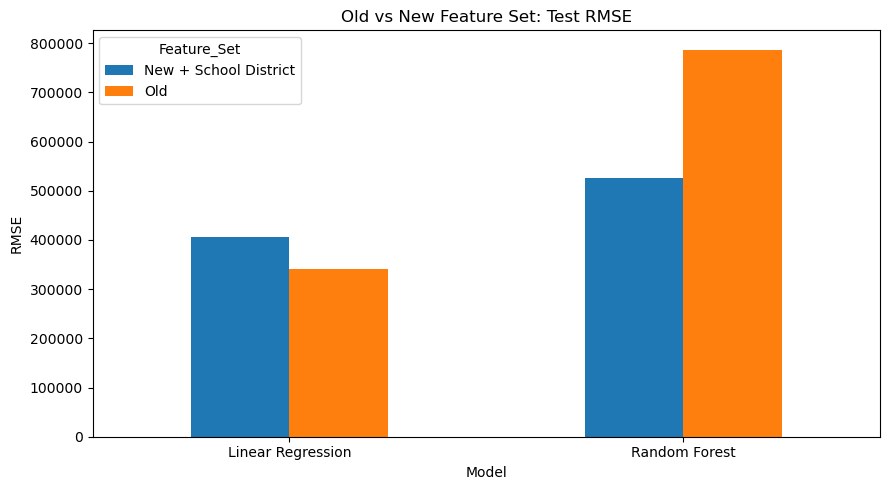

In [15]:

rmse_plot = comparison_table.pivot(
    index="Model",
    columns="Feature_Set",
    values="RMSE",
)

ax = rmse_plot.plot(kind="bar", figsize=(9, 5))
ax.set_title("Old vs New Feature Set: Test RMSE")
ax.set_xlabel("Model")
ax.set_ylabel("RMSE")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

plt.savefig(
    output_dir / "old_vs_new_rmse.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


## 16. Save the feature-engineered dataset

In [16]:

engineered_data_path = output_dir / "feature_engineered_data.csv"
df.to_csv(engineered_data_path, index=False)

print("Saved:", engineered_data_path)
print("Saved:", output_dir / "model_comparison_old_vs_new.csv")
print("Saved:", output_dir / "model_improvement_summary.csv")
print("Saved:", output_dir / "school_district_property_counts.csv")
print("Saved:", output_dir / "old_vs_new_rmse.png")


Saved: C:\Users\18327\IDX Exchange\results\Updated notebook + table comparing\feature_engineered_data.csv
Saved: C:\Users\18327\IDX Exchange\results\Updated notebook + table comparing\model_comparison_old_vs_new.csv
Saved: C:\Users\18327\IDX Exchange\results\Updated notebook + table comparing\model_improvement_summary.csv
Saved: C:\Users\18327\IDX Exchange\results\Updated notebook + table comparing\school_district_property_counts.csv
Saved: C:\Users\18327\IDX Exchange\results\Updated notebook + table comparing\old_vs_new_rmse.png


## 17. Automatic conclusion

In [17]:

for _, row in improvement_table.iterrows():
    model_name = row["Model"]
    rmse_change = row["RMSE_Improvement_Percent"]
    r2_change = row["R2_Change"]

    if rmse_change > 0:
        print(
            f"{model_name}: the new feature set reduced RMSE by "
            f"{rmse_change:.2f}% and changed R² by {r2_change:.4f}."
        )
    else:
        print(
            f"{model_name}: the new feature set increased RMSE by "
            f"{abs(rmse_change):.2f}% and changed R² by {r2_change:.4f}."
        )


Linear Regression: the new feature set increased RMSE by 19.17% and changed R² by -0.0326.
Random Forest: the new feature set reduced RMSE by 33.13% and changed R² by 0.2296.



## Deliverables produced

After running all cells, the `results/06` folder will contain:

- `feature_engineered_data.csv`
- `model_comparison_old_vs_new.csv`
- `model_improvement_summary.csv`
- `school_district_property_counts.csv`
- `old_vs_new_rmse.png`

Use `model_comparison_old_vs_new.csv` or `model_improvement_summary.csv` as the Week 6 old-versus-new feature comparison table.
